# Phase space of waves: Wigner, Husimi and ray chaos in microcavities

A ray is a point in phase space: a position and a direction. A wave is
spread over both, and there are two standard ways to draw it there.
The **Wigner function** (notebook 47) has exactly the right marginals,
intensity and spectrum, but oscillates and goes negative wherever two
ray sheets overlap. The **Husimi function** is the Wigner function
smoothed over one uncertainty cell: the squared overlap of the wave with
a Gaussian beamlet, never negative, readable as a ray density, at the
price of a resolution limit. It is the same object as a spectrogram,
as the local spectra that `raywave.local_spectrum_rays()` turns into
rays (notebook 48) and as the coefficients of a Gaussian beamlet
decomposition (notebook 56).

The second half uses the Husimi function where it is indispensable: in
the phase space of a **chaotic billiard**. Notebook 67 deformed a
microdisk into a limaçon and found that its modes emit along the axis,
and explained it in words with the ray picture of Wiersig and Hentschel.
Here the ray picture is computed:

1. Wigner and Husimi functions of 1D fields: a beam, two crossing beams,
   a caustic; the choice of the window;
2. billiards in **Birkhoff coordinates** (arc length, sine of the angle of
   incidence) and their Poincaré surfaces of section: the integrable
   circle, the mixed limaçon, the chaotic stadium (`pyoptics.billiard`);
3. the Husimi functions of FDFD modes on the boundary of the disk;
4. the limaçon: where the modes live in the surface of section;
5. the open, dielectric billiard: rays that leak by Fresnel refraction,
   the unstable manifold and the far field, against the FDFD modes;
6. the Bunimovich stadium, fully chaotic.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from pyoptics import billiard, fdfd, fdtd
from pyoptics import analytical as an
from pyoptics.raywave import wigner, husimi
from pyoptics.utils import grid1d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.perf_counter()

## 1. Wigner and Husimi functions of 1D fields

For a field $u(x)$ (a section through a beam, wavelength $\lambda$ =
1 µm) the Wigner function and the Husimi function with a window of
width $\sigma$ are

$$W(x, k) = \int u(x + s/2)\,u^*(x - s/2)\,e^{-iks}\,ds, \qquad
  H(x, k) = \Bigl|\int u(x')\,g_\sigma(x' - x)\,e^{-ikx'}\,dx'\Bigr|^2,$$

$g_\sigma(s) = (\pi\sigma^2)^{-1/4}e^{-s^2/2\sigma^2}$, with $k = k_0\sin\theta$
the transverse wavenumber of a ray at the angle $\theta$. $H$ is $W$
convolved with the Wigner function of the window, a Gaussian of widths
$\sigma/\sqrt2$ in $x$ and $1/(\sqrt2\sigma)$ in $k$; both integrate to the
power, $\iint W\,dx\,dk/2\pi = \iint H\,dx\,dk/2\pi = \int|u|^2dx$.
Three fields:

* a **Gaussian beam** behind its waist (a tilted ellipse: the wavefront
  curvature correlates $x$ and $k$),
* **two crossing beams**, tilted by ±0.1 rad and overlapping,
* a **fold caustic**: a field with the cubic spectral phase
  $U(k) \propto e^{-k^2/\kappa^2}e^{ibk^3}$, whose rays $x = -3bk^2$ form a
  parabola that folds back at $x = 0$; its intensity is an Airy function.

Gaussian beam       : ∫∫W = 1.000000, ∫∫H = 1.000000, min W/max W = -0.000, min H = 0.0e+00
two crossing beams  : ∫∫W = 1.000000, ∫∫H = 1.000000, min W/max W = -0.909, min H = 0.0e+00
fold caustic        : ∫∫W = 1.000000, ∫∫H = 0.999999, min W/max W = -0.404, min H = 0.0e+00


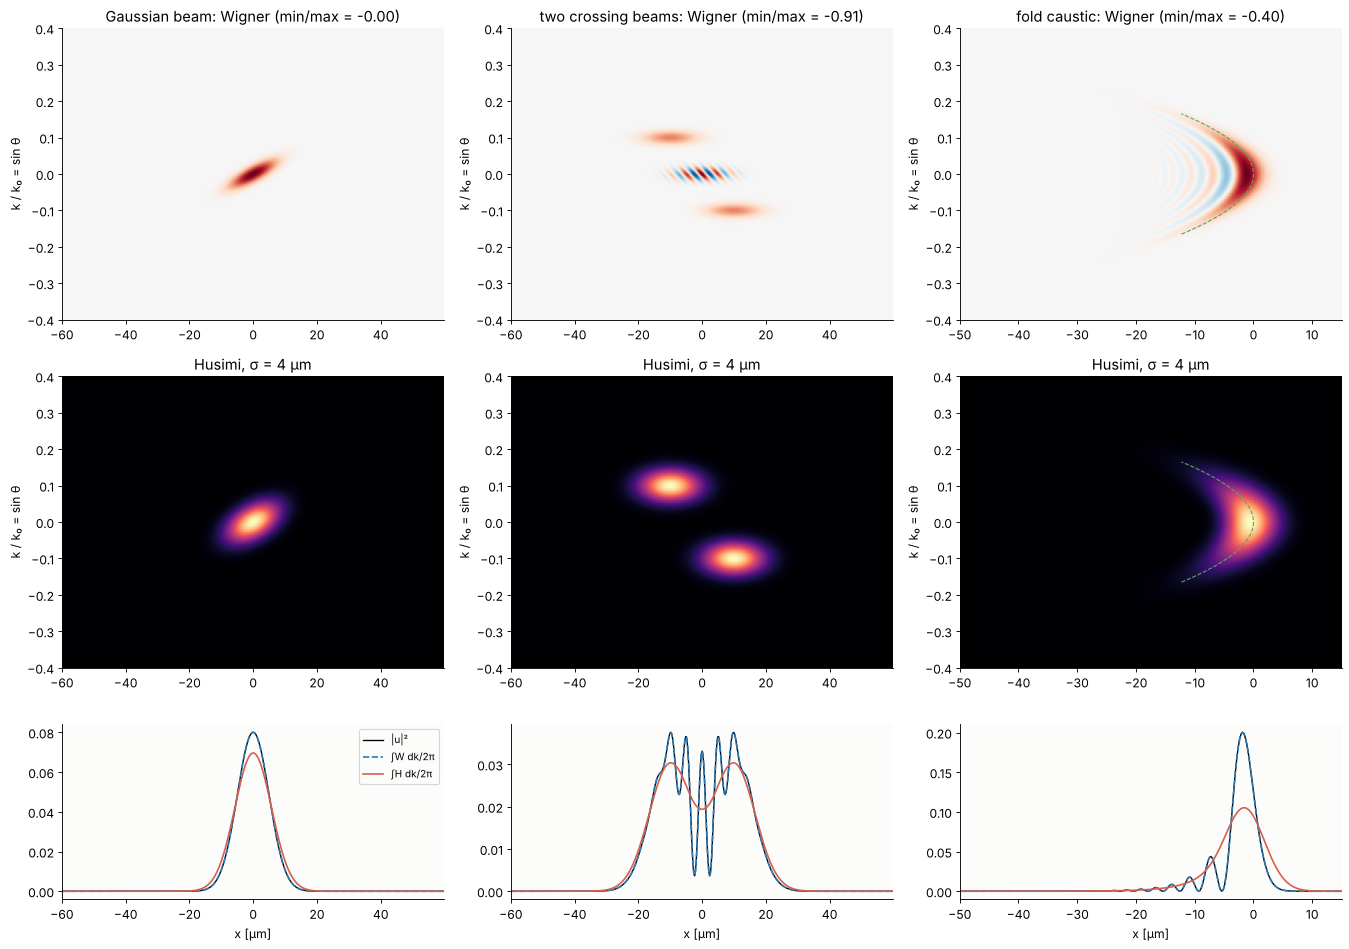

In [2]:
lam = 1.0
k0 = 2*np.pi/lam
x = grid1d(-60, 60, 512)
dx = x[1] - x[0]

# Gaussian beam: waist 6 µm, 150 µm behind the waist
w0, z = 6.0, 150.0
zR = np.pi*w0**2/lam
q = z - 1j*zR
u_beam = np.exp(1j*k0*x**2/(2*q))

# two crossing beams
u_two = sum(np.exp(-(x - x0)**2/12.0**2)*np.exp(1j*k0*a*x) for x0, a in ((-10, 0.1), (10, -0.1)))

# fold caustic from a cubic spectral phase
kk = 2*np.pi*np.fft.fftfreq(len(x), dx)
kappa, b = 0.15*k0, 150.0/k0**2           # rays x = -3 b k^2: x = -40 µm at k = 0.3 k0
U = np.exp(-kk**2/kappa**2)*np.exp(1j*b*kk**3)
u_fold = np.fft.fftshift(np.fft.ifft(U))         # centred on x = 0
k_ray = np.linspace(-1.1*kappa, 1.1*kappa, 200)
x_ray = -3*b*k_ray**2

fields = [("Gaussian beam", u_beam), ("two crossing beams", u_two), ("fold caustic", u_fold)]
sigma = 4.0
fig, axes = plt.subplots(3, 3, figsize=(17, 12), gridspec_kw={"height_ratios": [1, 1, 0.6]})
for col, (name, u) in enumerate(fields):
    u = u/np.sqrt(np.sum(np.abs(u)**2)*dx)
    kw, W = wigner(u, x)
    kh, H = husimi(u, x, sigma)
    lim = np.abs(W).max()
    ext_w = [x[0], x[-1], kw[0]/k0, kw[-1]/k0]
    axes[0, col].imshow(W, extent=ext_w, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[1, col].imshow(H, extent=[x[0], x[-1], kh[0]/k0, kh[-1]/k0], origin="lower", aspect="auto",
                        cmap="magma")
    for row in (0, 1):
        axes[row, col].set_ylim(-0.4, 0.4)
        axes[row, col].set_ylabel("k / k₀ = sin θ")
    if name == "fold caustic":
        for row in (0, 1):
            axes[row, col].plot(x_ray, k_ray/k0, color=GREEN, lw=1, ls="--")
            axes[row, col].set_xlim(-50, 15)
    axes[0, col].set_title(f"{name}: Wigner (min/max = {W.min()/W.max():+.2f})")
    axes[1, col].set_title(f"Husimi, σ = {sigma:g} µm")
    I = np.abs(u)**2
    axes[2, col].plot(x, I, color="k", lw=1.2, label="|u|²")
    axes[2, col].plot(x, W.sum(0)*(kw[1] - kw[0])/(2*np.pi), color=BLUE, ls="--", label="∫W dk/2π")
    axes[2, col].plot(x, H.sum(0)*(kh[1] - kh[0])/(2*np.pi), color=RED, label="∫H dk/2π")
    axes[2, col].set_xlabel("x [µm]")
    axes[2, col].set_xlim(axes[0, col].get_xlim())
    print(f"{name:20s}: ∫∫W = {W.sum()*dx*(kw[1]-kw[0])/(2*np.pi):.6f}, ∫∫H = {H.sum()*dx*(kh[1]-kh[0])/(2*np.pi):.6f}, "
          f"min W/max W = {W.min()/W.max():+.3f}, min H = {H.min():.1e}")
axes[2, 0].legend(fontsize=9)
plt.tight_layout()

The Gaussian beam is the one field for which both are simple: positive
Gaussians on the same tilted ellipse, the Husimi blob larger by the
window. The crossing beams are two blobs at $k/k_0 = \pm0.1$; the
Wigner function adds a third, oscillating one halfway between them in
phase space, at $k = 0$, where there is no light going anywhere: the
interference term, as large as the beams themselves and half negative.
It is what makes the fringes in the intensity (blue dashed, exact), and
the Husimi marginal (red) smooths them away. For the caustic the
Wigner function fills the inside of the ray parabola with Airy fringes
of both signs; the Husimi function is a smooth band along the parabola,
the rays, broadened by the window, and leaks a little past the fold
into the shadow at $x > 0$ (as the wave does).

The width of the window decides what is resolved: narrow windows
resolve $x$, wide ones $k$, and the product of the two resolutions is
fixed. For a curved ray manifold the best compromise follows its
slope:

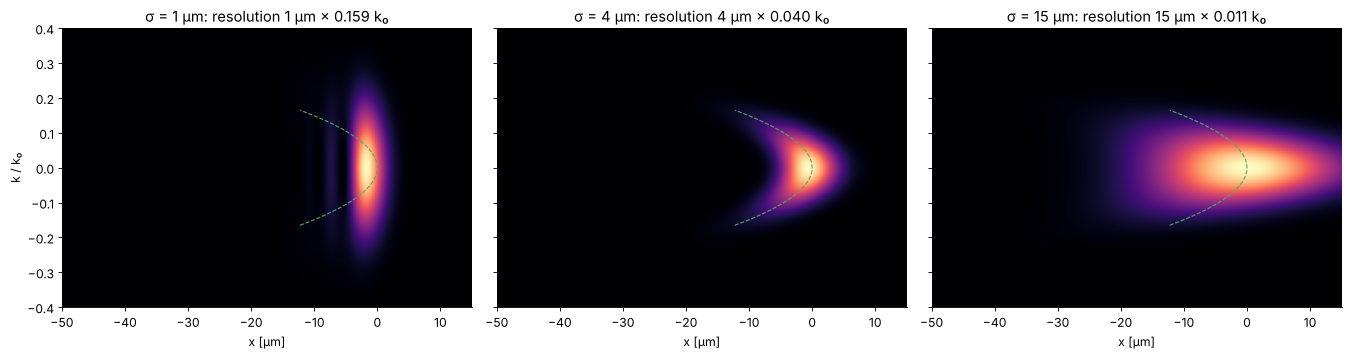

In [3]:
u = u_fold/np.sqrt(np.sum(np.abs(u_fold)**2)*dx)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for ax, sg in zip(axes, (1.0, 4.0, 15.0)):
    kh, H = husimi(u, x, sg)
    ax.imshow(H, extent=[x[0], x[-1], kh[0]/k0, kh[-1]/k0], origin="lower", aspect="auto", cmap="magma")
    ax.plot(x_ray, k_ray/k0, color=GREEN, lw=1, ls="--")
    ax.set_xlim(-50, 15); ax.set_ylim(-0.4, 0.4)
    ax.set_title(f"σ = {sg:g} µm: resolution {sg:g} µm × {1/(sg*k0):.3f} k₀")
    ax.set_xlabel("x [µm]")
axes[0].set_ylabel("k / k₀")
plt.tight_layout()

With $\sigma$ = 1 µm the window is shorter than the spacing of the
rays that cross at each $x$ and the band smears out in $k$; with 15 µm
it averages over a stretch of the parabola where $k$ changes and
smears in $x$. Around 4 µm both rays of each $x$ are separated.

The same function appears elsewhere in the library under other names.
`raywave.local_spectrum_rays()` (notebook 48) cuts a 2D field into
Gaussian windows and turns every strong component of the local spectra
into a ray: those rays sample the 2D Husimi function. Projected on
Gaussian beamlets at a lattice of positions *and* directions (a Gabor
frame), a field has coefficients whose squared moduli are the Husimi
function on that lattice; the beamlet decomposition of notebook 56 takes
one beamlet per position with the local tilt instead. In ultrafast optics the spectrogram of a pulse (time and
frequency instead of $x$ and $k$) is the same object again.

## 2. Billiards and the surface of section

A billiard is the simplest dynamics with walls: a ray runs straight
inside a closed curve and is reflected specularly. Between two bounces it
is fixed by the point on the boundary and the direction, in **Birkhoff
coordinates**: the arc length $s$ along the boundary (from the point on
the $+x$ axis, counter-clockwise) and $p = \sin\chi$, the tangential
component of the direction ($\chi$ the angle of incidence from the
normal, positive for rays running counter-clockwise). The bounce map
$(s, p) \to (s', p')$ is the Poincaré map of the billiard; it preserves
the area $ds\,dp$ (Liouville's theorem, notebook 83, on the surface of
section), and a plot of many bounces of a few rays, the **surface of
section**, shows the character of the dynamics at a glance.

The ray tracer of `pyoptics.raytrace` follows rays through a sequence of
surfaces along an axis and cannot do this. `pyoptics.billiard` iterates
the map for any convex `fdtd.PolarShape`, the same shapes the FDTD and
FDFD draw: the chord from the current bounce to the next intersection
is found by bisection on the polar angle and polished by Newton steps,
for many rays at once. Three shapes of the same area:

144000 bounces in 1.7 s


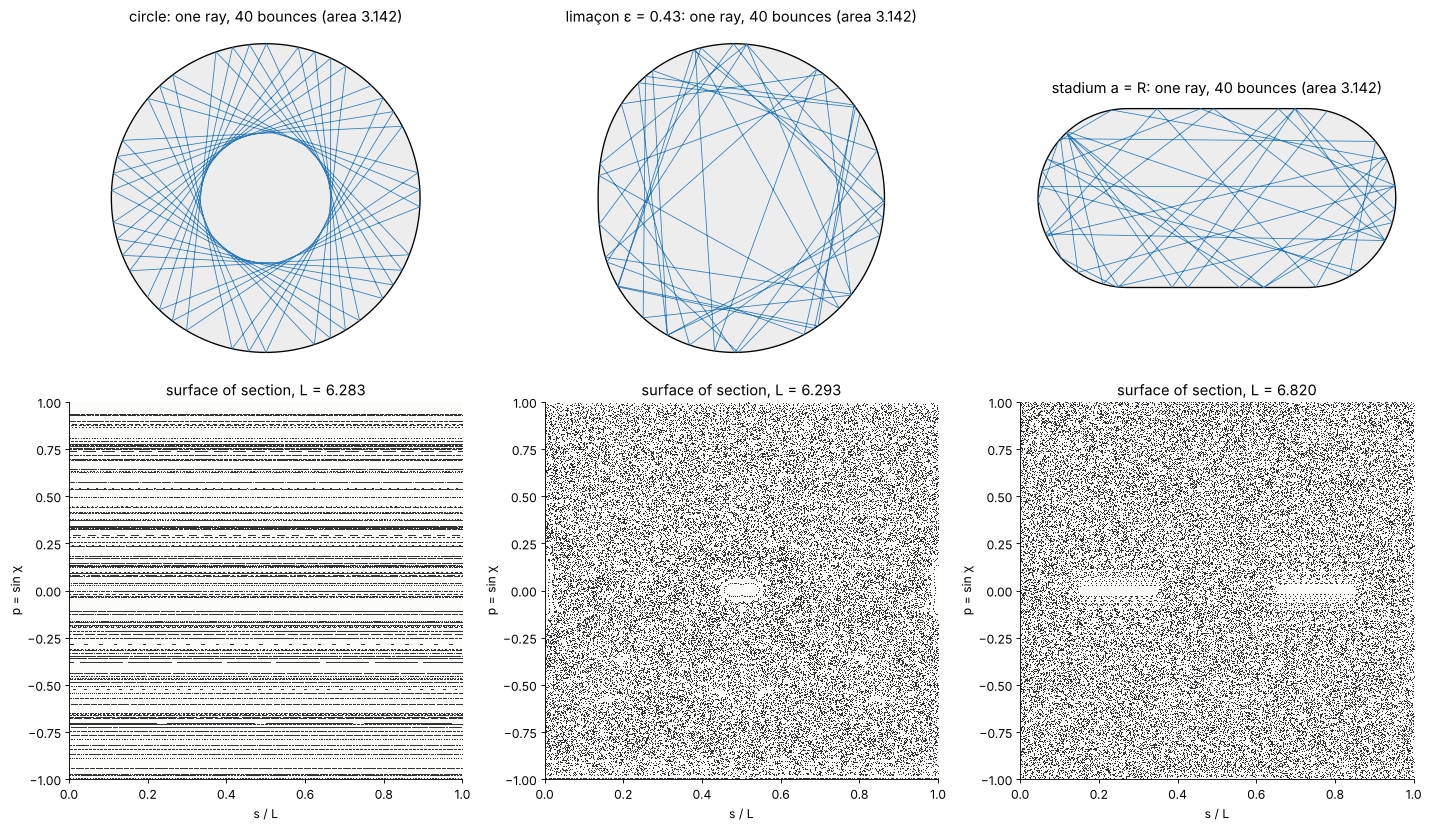

In [4]:
R0 = 1.0
shapes = {
    "circle": fdtd.Limacon((0, 0), R0, 0.0),
    "limaçon ε = 0.43": fdtd.Limacon((0, 0), R0/np.sqrt(1 + 0.43**2/2), 0.43),
    "stadium a = R": fdtd.Stadium((0, 0), R0*np.sqrt(np.pi/(np.pi + 4)), R0*np.sqrt(np.pi/(np.pi + 4))),
}
t0 = time.perf_counter()
fig, axes = plt.subplots(2, 3, figsize=(18, 10.5), gridspec_kw={"height_ratios": [0.9, 1]})
sos = {}
for col, (name, shp) in enumerate(shapes.items()):
    B = billiard.Billiard(shp)
    # one long orbit in real space
    S1, P1 = B.orbit(0.13*B.length, 0.42, 40)
    pts = B.point(B.polar_angle(S1[:, 0]))
    bd = shp.boundary(721)
    axes[0, col].fill(bd[:, 0], bd[:, 1], color="0.93", ec="k", lw=1.2)
    axes[0, col].plot(pts[:, 0], pts[:, 1], color=BLUE, lw=0.7)
    axes[0, col].set_aspect("equal"); axes[0, col].axis("off")
    axes[0, col].set_title(f"{name}: one ray, 40 bounces (area {shp.area():.3f})")
    # surface of section: 120 random rays, 400 bounces each
    S, P = B.surface_of_section(n_rays=120, n_bounces=400, seed=3)
    sos[name] = (B, S, P)
    axes[1, col].plot(S.ravel()/B.length, P.ravel(), ",", color="0.2", rasterized=True)
    axes[1, col].set_xlabel("s / L"); axes[1, col].set_ylabel("p = sin χ")
    axes[1, col].set_xlim(0, 1); axes[1, col].set_ylim(-1, 1)
    axes[1, col].set_title(f"surface of section, L = {B.length:.3f}")
print(f"{3*120*400} bounces in {time.perf_counter() - t0:.1f} s")
plt.tight_layout()

In the **circle** every ray keeps its angle of incidence: $p$ is the
angular momentum, conserved, and each orbit is a horizontal line (or a
finite set of points, for the periodic orbits with rational
$\arccos p/\pi$). The billiard is integrable. The **limaçon** at
$\varepsilon = 0.43$ (the deformation of notebook 67) is almost fully
chaotic: single orbits wander over the whole surface of section, the
chaotic sea, apart from small regular islands around the stable
two-bounce orbit along the axis, which shows up at both of its bounce
points, $s = 0$ and $s = L/2$, $p = 0$. The **stadium** (two half discs
joined by straight sides as long as the radius) is fully chaotic
(Bunimovich 1979): no islands at all. The empty boxes at $p \approx 0$ on
the straight sides ($0.15 < s/L < 0.35$ and $0.65 < s/L < 0.85$) are the
bouncing-ball orbits between the two sides, a marginally stable family
that a chaotic orbit enters only rarely.

## 3. The Husimi function of a mode on the boundary

A mode of a cavity is a wave inside a billiard. Its counterpart of the
surface of section is a Husimi function on the boundary (Hentschel,
Schomerus and Schubert 2003): near a boundary point the wave is a sum of
plane waves with the tangential wavenumber $nkp$, each travelling
towards the boundary or away from it. From the field $\psi$ and its
normal derivative $\partial_\nu\psi$ on the boundary the two parts are
$(\psi \pm \partial_\nu\psi/(ink\cos\chi))/2$; projected on coherent
states along $s$ with the momentum $nkp$ and weighted with the flux
factor $\cos\chi$, they give the **incident** Husimi function
$H^{\rm inc}(s, p)$, the wave counterpart of the rays arriving at the
boundary, and the reflected one. For the Ez polarization both $\psi$ and
$\partial_\nu\psi$ are continuous across the boundary, so
`fdfd.husimi_birkhoff()` takes them from the FDFD grid by cubic
interpolation and a central difference across the rim. The window along
$s$ is $\sigma = \sqrt{L/2nk}$: the same fraction of the range in $s$
($L$) and in $p$ (2).

The GaAs disk of notebook 67 ($R$ = 1.8 µm, $n$ = 3.3) has, near
1.54 µm, whispering gallery modes of three radial orders. In the
circle each sits on a line $p = m/(nkR)$:

m = 13: m/(nkR) = 0.5346, Husimi peak |p| = 0.530, incident/reflected = 1.00024, Q = 1.81e+05


m = 16: m/(nkR) = 0.6633, Husimi peak |p| = 0.660, incident/reflected = 1.00000, Q = 3.55e+07


m = 20: m/(nkR) = 0.8260, Husimi peak |p| = 0.830, incident/reflected = 1.00000, Q = 1.5e+07
17 s


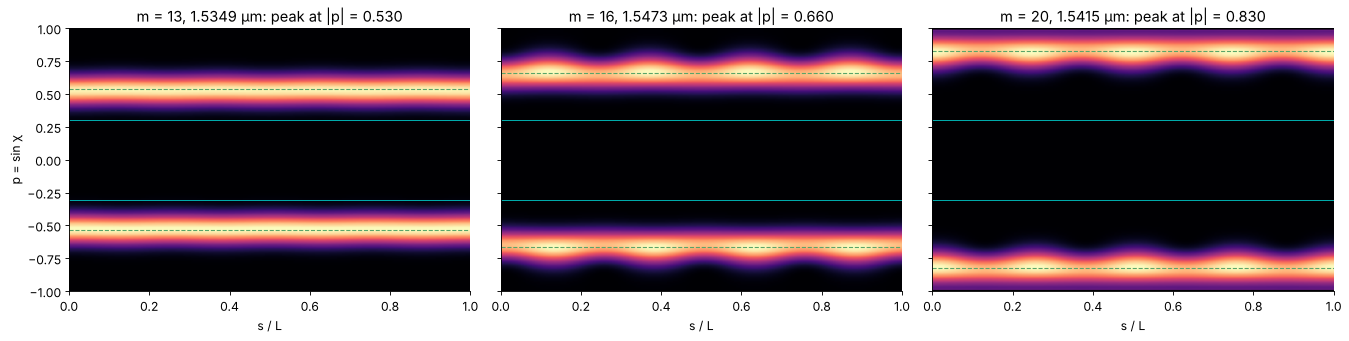

In [5]:
n_gaas, R = 3.3, 1.8
gaas = fdtd.Medium.from_index(n_gaas)
h = 0.0225                                   # the cell of notebook 67
N = int(round(6.8/h)) | 1
grid = fdtd.Grid((N*h, N*h), h, center=(h/2, h/2))
disk = fdtd.Limacon((0, 0), R, 0.0)
t0 = time.perf_counter()
k_ex = an.disk_resonance(20, R, n_gaas, 1.54)
modes0 = fdfd.Simulation(grid, [(disk, gaas)]).resonances(2*np.pi/k_ex.real, n=6)
disk_b = billiard.Billiard(disk)


def azimuthal_number(r):
    mm, c = fdfd.circle_harmonics(r.field, 0.95*R)
    return abs(mm[np.argmax(np.abs(c))])


picked = {}
for r in modes0:
    picked.setdefault(azimuthal_number(r), r)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), sharey=True)
for ax, m in zip(axes, sorted(picked)):
    r = picked[m]
    q, p, H_inc, H_ref = fdfd.husimi_birkhoff(r.field, disk_b, n_gaas)
    p_wgm = billiard.circle_wgm_p(m, n_gaas, r.omega.real, R)
    ax.imshow(H_inc, extent=[0, 1, -1, 1], origin="lower", aspect="auto", cmap="magma")
    for sgn in (1, -1):
        ax.axhline(sgn*p_wgm, color=GREEN, ls="--", lw=1)
        ax.axhline(sgn/n_gaas, color="c", lw=0.8)
    p_peak = abs(p[np.argmax(H_inc.sum(1))])
    ax.set_title(f"m = {m}, {r.wavelength:.4f} µm: peak at |p| = {p_peak:.3f}")
    ax.set_xlabel("s / L")
    print(f"m = {m}: m/(nkR) = {p_wgm:.4f}, Husimi peak |p| = {p_peak:.3f}, "
          f"incident/reflected = {H_inc.sum()/H_ref.sum():.5f}, Q = {r.Q:.3g}")
axes[0].set_ylabel("p = sin χ")
print(f"{time.perf_counter() - t0:.0f} s")
plt.tight_layout()

Each mode is a standing wave $\cos m\varphi$ or $\sin m\varphi$, the sum of
a counter-clockwise ($p > 0$) and a clockwise ($p < 0$) wave, so the
Husimi function has two bands, uniform along $s$, at the angular momentum
$p = m/(nkR)$ (green): the WGM of the lowest radial order ($m$ = 20) at
the largest angle of incidence, $\chi$ = 56°, the higher radial orders
further in. Incident and reflected Husimi functions agree to the
numerical error: a mode of high Q reflects (almost) everything. All
three bands lie far above the critical lines $|p| = 1/n$ (cyan), the
limit of total internal reflection: a ray there never leaves, and the
wave leaks only by tunnelling, hence the enormous Q.

The bands are 0.2 wide in $p$: the uncertainty cell. The surface of
section of this cavity holds $2L\,nk/2\pi \approx 50$ cells, so it is
a coarse picture; for the limaçon we also take a cavity twice as large.

## 4. The limaçon: where the modes live

Two GaAs limaçons at $\varepsilon = 0.43$: the one of notebook 67
($R$ = 1.8 µm, $nkR \approx 23$, about 50 cells in the surface of section) and
one of twice the size ($R$ = 3.6 µm, about 100 cells), on the same grid,
with the longest-lived modes near 1.6 µm. The grid of the large one is
centred on the cavity, which is not centred on the origin of the
limaçon.

In [6]:
eps = 0.43


def limacon_cavity(Rc):
    shp = fdtd.Limacon((0, 0), Rc, eps)
    bd = shp.boundary(2001)
    cx = round(0.5*(bd[:, 0].max() + bd[:, 0].min())/h)*h
    rho = np.hypot(bd[:, 0] - cx, bd[:, 1]).max() + 0.3     # circle of the far-field expansion
    Nc = int(round(2*(rho + 0.6)/h)) | 1                       # odd: nodes symmetric in y
    g = fdtd.Grid((Nc*h, Nc*h), h, center=(cx + h/2, h/2))
    return shp, fdfd.Simulation(g, [(shp, gaas)]), (cx, 0.0), rho


def distinct(modes, tol=1e-6):
    out = []
    for r in sorted(modes, key=lambda r: -r.Q):
        if not any(abs(r.omega - o.omega) < tol*abs(r.omega) for o in out):
            out.append(r)
    return out


t0 = time.perf_counter()
cav = {}
for Rc, guesses in ((1.8, (1.612,)), (3.6, (1.60,))):
    shp, sim, ctr, rho = limacon_cavity(Rc)
    found = []
    for g in guesses:
        found += sim.resonances(g, n=14, refine=0)
    cav[Rc] = dict(shape=shp, sim=sim, center=ctr, rho=rho, B=billiard.Billiard(shp),
                   modes=[r for r in distinct(found) if r.Q > 100])
    print(f"R = {Rc} µm: grid {sim.grid.shape}, {len(cav[Rc]['modes'])} modes with Q > 100, best Q "
          f"{', '.join(f'{r.Q:.3g}' for r in cav[Rc]['modes'][:6])}")
print(f"{time.perf_counter() - t0:.0f} s")

R = 1.8 µm: grid (255, 255), 10 modes with Q > 100, best Q 6.49e+03, 6.46e+03, 2e+03, 1.91e+03, 697, 686


R = 3.6 µm: grid (429, 429), 13 modes with Q > 100, best Q 9.33e+04, 8.71e+04, 1.33e+04, 1.23e+04, 2.94e+03, 2.92e+03
11 s


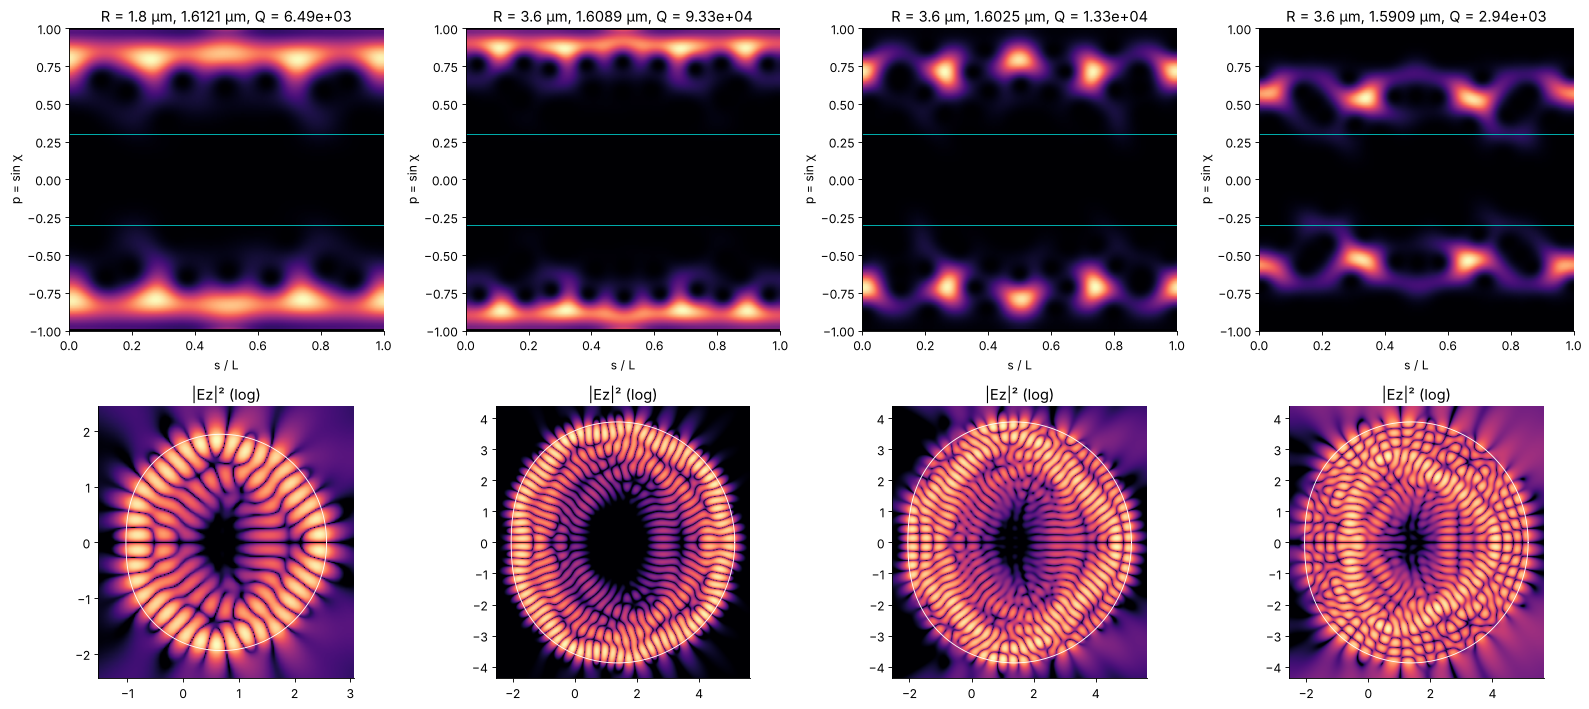

In [7]:
show = [(1.8, cav[1.8]["modes"][0]), (3.6, cav[3.6]["modes"][0]), (3.6, cav[3.6]["modes"][2]),
        (3.6, cav[3.6]["modes"][4])]
fig, axes = plt.subplots(2, 4, figsize=(20, 9), gridspec_kw={"height_ratios": [1, 0.9]})
for col, (Rc, r) in enumerate(show):
    c = cav[Rc]
    q, p, H_inc, _ = fdfd.husimi_birkhoff(r.field, c["B"], n_gaas, q=np.linspace(0, c["B"].length, 300, endpoint=False))
    ax = axes[0, col]
    ax.imshow(H_inc/H_inc.max(), extent=[0, 1, -1, 1], origin="lower", aspect="auto", cmap="magma")
    for sgn in (1, -1):
        ax.axhline(sgn/n_gaas, color="c", lw=0.8)
    ax.set_title(f"R = {Rc} µm, {r.wavelength:.4f} µm, Q = {r.Q:.3g}")
    ax.set_xlabel("s / L"); ax.set_ylabel("p = sin χ")
    ax = axes[1, col]
    xs, ys = r.field.coords["Ez"]
    I = np.abs(r.field.main.T)**2
    ax.imshow(I/I.max(), extent=[xs[0], xs[-1], ys[0], ys[-1]], origin="lower", cmap="magma", norm=LogNorm(1e-4, 1))
    bd = c["shape"].boundary(721)
    ax.plot(bd[:, 0], bd[:, 1], color="w", lw=0.8)
    ax.set_aspect("equal")
    ax.set_xlim(bd[:, 0].min() - 0.5, bd[:, 0].max() + 0.5); ax.set_ylim(bd[:, 1].min() - 0.5, bd[:, 1].max() + 0.5)
    ax.set_title("|Ez|² (log)")
plt.tight_layout()

The long-lived modes keep away from the critical lines (cyan). The
mode of notebook 67 (left) fills the band $0.5 \lesssim |p| < 1$ with a
few maxima: the cavity is too small to show more. In the large cavity
the longest-lived mode is still a whispering gallery mode near
$|p| = 1$, modulated by the shape. The next ones, with Q of $10^4$ and
$3\cdot10^3$, sit lower, in the chaotic sea, and reach down to the
critical line at a few places along $s$. None of them sits in the
regular islands at $p = 0$, which are smaller than one cell. The
question is how they leak.

## 5. The open billiard: how the light leaves

In the dielectric cavity a ray is not reflected completely: at each
bounce the Fresnel reflectance $R(\chi)$ (s polarization for Ez) keeps
part of it and the rest leaves by refraction, at the angle
$\sin\chi_{\rm out} = n\sin\chi$; above the critical line it stays
(total internal reflection). Started uniformly in phase space and
weighted with the product of its reflectances, a ray ensemble settles
after a transient into a fixed distribution over the surface of section
that decays as a whole, the **steady probability distribution** (Lee
et al. 2004, Shinohara and Harayama 2007). In a chaotic cavity it
traces out the **unstable manifold** of the chaotic saddle: the light that
survives longest reaches the leaky region $|p| < 1/n$ only along
narrow tongues, and those tongues decide where on the boundary and in
which directions it leaves. `billiard.steady_distribution()` and
`billiard.escape_directions()` compute both, here for the large limaçon
(the shape is the same for both sizes, only the scale of $s$ differs).

40000 rays × 60 bounces in 10.5 s; steady loss per bounce 0.0130


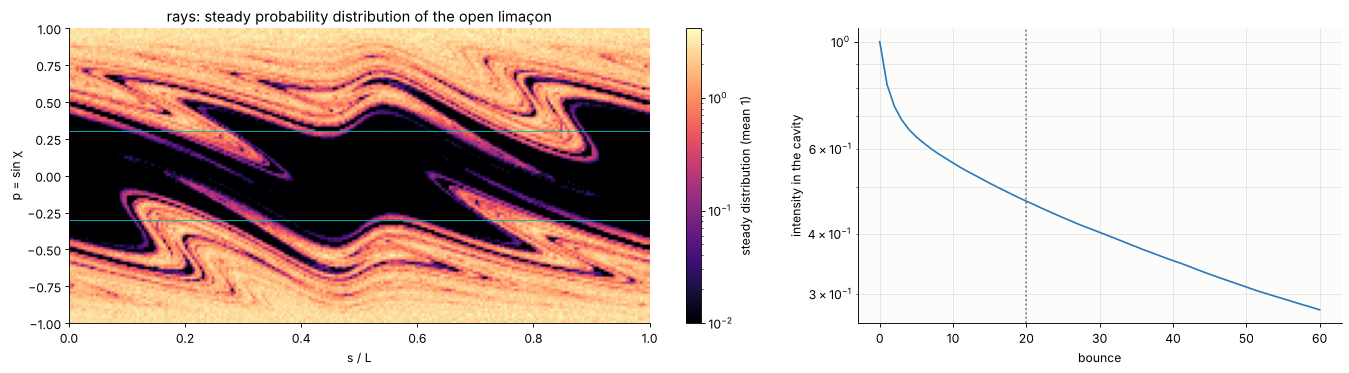

In [8]:
t0 = time.perf_counter()
rng = np.random.default_rng(0)
B = cav[3.6]["B"]
Nr, n_b, skip = 40000, 60, 20
S0, P0 = B.orbit(rng.uniform(0, B.length, Nr), rng.uniform(-1, 1, Nr), n_b)
s_e, p_e, D, decay = billiard.steady_distribution(S0, P0, n_gaas, B.length, bins=(240, 120), skip=skip)
phi_r, I_r = billiard.escape_directions(B, S0, P0, n_gaas, bins=180, skip=skip)
loss = -np.log(decay[-1]/decay[skip])/(n_b - skip)
print(f"{Nr} rays × {n_b} bounces in {time.perf_counter() - t0:.1f} s; steady loss per bounce {loss:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
im = axes[0].imshow(D, extent=[0, 1, -1, 1], origin="lower", aspect="auto", cmap="magma",
                    norm=LogNorm(1e-2, D.max()))
plt.colorbar(im, ax=axes[0], label="steady distribution (mean 1)")
for sgn in (1, -1):
    axes[0].axhline(sgn/n_gaas, color="c", lw=0.8)
axes[0].set_xlabel("s / L"); axes[0].set_ylabel("p = sin χ")
axes[0].set_title("rays: steady probability distribution of the open limaçon")
axes[1].semilogy(np.arange(n_b + 1), decay, color=BLUE)
axes[1].axvline(skip, color=GREY, ls=":")
axes[1].set_xlabel("bounce"); axes[1].set_ylabel("intensity in the cavity")
axes[1].grid(alpha=0.3, which="both")
plt.tight_layout()

After about ten bounces the decay is exponential. The rays still in
the cavity are spread over the whole chaotic sea above the critical
lines, but below them they are confined to thin, S-shaped filaments:
the unstable manifold. Rays reach the leaky region only along those
filaments.

A mode cannot resolve the filaments; its Husimi function is a ray
density seen through one coherent state. A fair comparison smooths the
ray distribution the same way: with the Wigner function of the coherent
state, a Gaussian of widths $\sigma/\sqrt2$ in $s$ and
$1/(\sqrt2\,\sigma nk)$ in $p$. Below, the leaky region and its
surroundings, $|p| < 0.4$, each panel scaled to its largest value below
the critical line (and saturated above it), with the correlation
coefficient between rays and mode for $|p| < 1/n$:

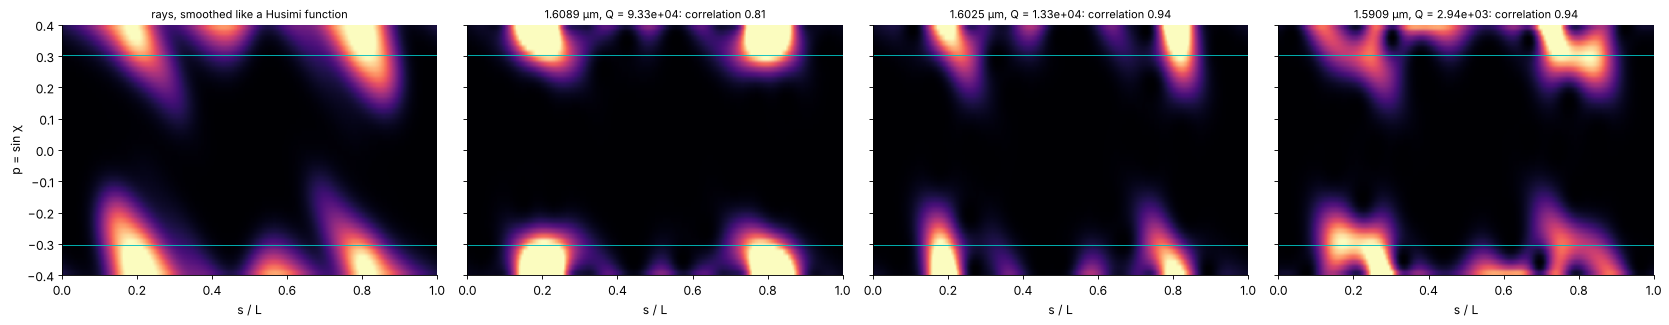

In [9]:
from scipy.ndimage import gaussian_filter


def smooth_like_husimi(D, s_e, p_e, length, k):
    """Ray distribution blurred with the Wigner function of the coherent states of husimi_birkhoff()."""
    sg = np.sqrt(length/(2*n_gaas*k))
    widths = (1/(np.sqrt(2)*sg*n_gaas*k)/(p_e[1] - p_e[0]), sg/np.sqrt(2)/(s_e[1] - s_e[0]))
    return gaussian_filter(D, widths, mode=("nearest", "wrap"))


def leaky_comparison(axes, D, s_e, p_e, B, modes, pmax=0.4):
    sc, pc = 0.5*(s_e[1:] + s_e[:-1]), 0.5*(p_e[1:] + p_e[:-1])
    band, leaky = np.abs(pc) < pmax, np.abs(pc) < 1/n_gaas
    Dsm = smooth_like_husimi(D, s_e, p_e, B.length, modes[0].omega.real)
    panels = [("rays, smoothed like a Husimi function", Dsm, None)]
    for r in modes:
        _, _, H, _ = fdfd.husimi_birkhoff(r.field, B, n_gaas, q=sc, p=pc)
        cc = np.corrcoef(H[leaky].ravel(), Dsm[leaky].ravel())[0, 1]
        panels.append((f"{r.wavelength:.4f} µm, Q = {r.Q:.3g}: correlation {cc:.2f}", H, cc))
    for ax, (title, A, cc) in zip(axes, panels):
        ax.imshow(A[band]/A[leaky].max(), extent=[0, 1, -pmax, pmax], origin="lower", aspect="auto", cmap="magma",
                  vmin=0, vmax=1)
        for sgn in (1, -1):
            ax.axhline(sgn/n_gaas, color="c", lw=0.8)
        ax.set_title(title, fontsize=10); ax.set_xlabel("s / L")
    axes[0].set_ylabel("p = sin χ")
    return [cc for _, _, cc in panels[1:]]


fig, axes = plt.subplots(1, 4, figsize=(21, 4.2), sharey=True)
cc_lim = leaky_comparison(axes, D, s_e, p_e, B, [show[1][1], show[2][1], show[3][1]])
plt.tight_layout()

In the leaky band all three modes have their weight where the smoothed
rays have theirs: on the two tongues that cross the critical lines
near $s/L \approx 0.2$ and 0.8 (on both sides of the flattened end of
the limaçon), with correlations of
0.8 to 0.95, and almost nothing at $p \approx 0$ next to the regular
islands. The light leaves a mode where rays leave the cavity, even for
the WGM, whose weak leakage takes the same route. The far field
follows: every leaking ray leaves in the direction given by Snell's law
at its boundary point; their histogram (grey) has a strong beam along
the axis, $\varphi = 0$, and weaker ones near ±140°. The FDFD far fields
(`fdfd.farfield()`) of the modes, in both cavities:

R = 1.8, 1.6121 µm, Q = 6.49e+03: directionality U = +0.168
R = 3.6, 1.6089 µm, Q = 9.33e+04: directionality U = +0.034
R = 3.6, 1.6025 µm, Q = 1.33e+04: directionality U = +0.198
R = 3.6, 1.5909 µm, Q = 2.94e+03: directionality U = +0.217
rays: U = +0.267


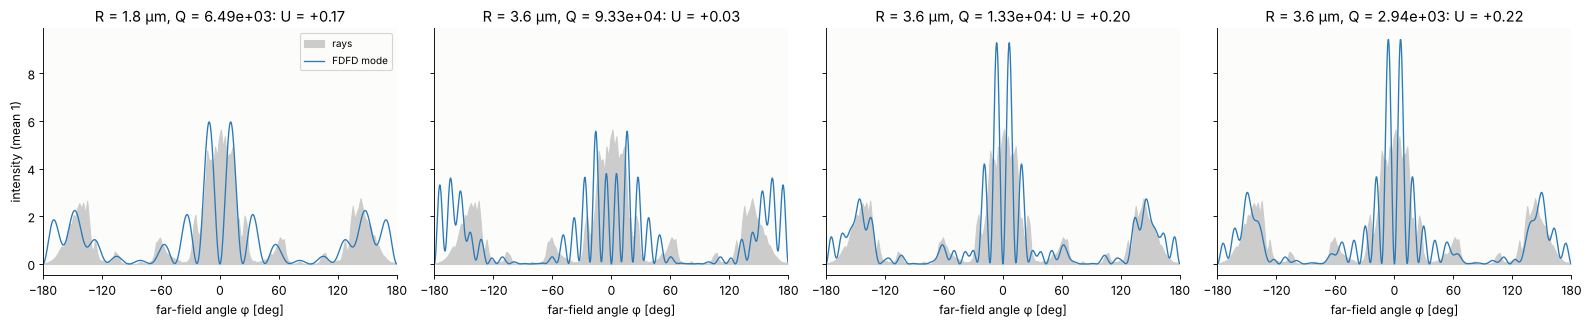

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2), sharey=True)
for ax, (Rc, r) in zip(axes, show):
    c = cav[Rc]
    ff = fdfd.farfield(r.field, c["rho"], center=c["center"])
    ax.fill_between(np.degrees(phi_r), I_r, color="0.8", label="rays")
    ax.plot(np.degrees(ff.phi), ff.intensity, color=BLUE, lw=1.2, label="FDFD mode")
    ax.set_xlim(-180, 180); ax.set_xticks(range(-180, 181, 60))
    ax.set_xlabel("far-field angle φ [deg]")
    ax.set_title(f"R = {Rc} µm, Q = {r.Q:.3g}: U = {ff.directionality():+.2f}")
    print(f"R = {Rc}, {r.wavelength:.4f} µm, Q = {r.Q:.3g}: directionality U = {ff.directionality():+.3f}")
axes[0].set_ylabel("intensity (mean 1)"); axes[0].legend(fontsize=9)
U_rays = np.sum(I_r*np.cos(phi_r))/np.sum(I_r)
print(f"rays: U = {U_rays:+.3f}")
plt.tight_layout()

The modes of the chaotic sea, in both cavities, reproduce the ray far
field: the beam along the axis and the side lobes near ±140°, with
interference fringes, because the wave leaves through two narrow places
on the boundary and adds amplitudes where the rays add intensities.
Their directionality $U$ is about 0.2 for all of them (the rays: 0.27),
which is the point of Wiersig and Hentschel's design: the direction of
emission is set by the unstable manifold, a property of the shape, not
of the mode. The WGM of the large cavity has the forward beam too, but
also strong lobes near ±165°, so its $U$ is small.
This is the ray picture that notebook 67 (section 5) referred to.

## 6. The stadium

The same analysis for a fully chaotic cavity: a GaAs stadium with the
straight sides as long as the radius ($R_s = a$ = 2.4 µm, about the area
of the large limaçon). Without regular regions there are no
whispering gallery modes; the rays leak seven times faster than in the
limaçon, and the Q values are lower. The steady distribution has a
different unstable manifold, and holes at the bouncing-ball orbits,
which hit the straight sides at normal incidence and leak at once.

grid (507, 507), best Q 2.28e+03, 709, 481, 459; ray loss per bounce 0.092 (limaçon 0.013); 26 s


far-field correlation with the rays (rays resampled to the mode angles):
  Q =   2284: -0.36
  Q =    709: +0.19
  Q =    481: +0.51
  Q =    459: +0.07
  Q =    439: -0.24
  Q =    421: +0.23
  Q =    405: +0.24
  Q =    386: +0.55
  Q =    288: +0.46
  Q =    266: +0.24
  Q =    247: +0.22
  Q =    230: -0.13
  mean of the modes: +0.58


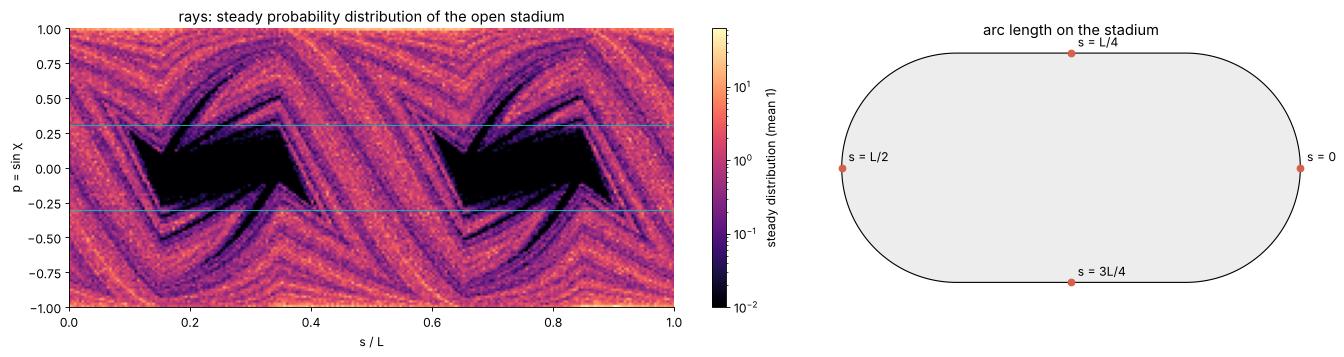

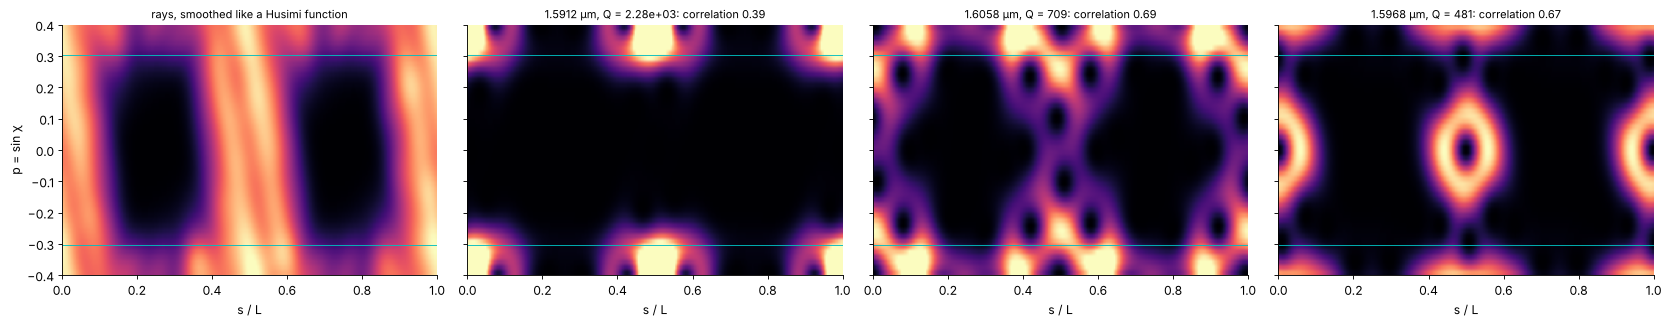

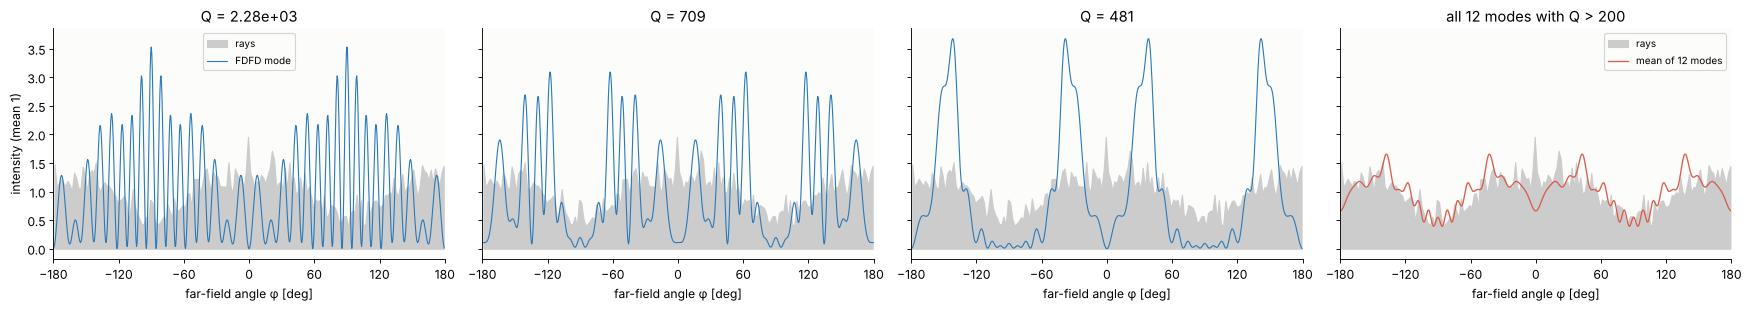

In [11]:
t0 = time.perf_counter()
Rs = 2.4
st = fdtd.Stadium((0, 0), Rs, Rs)
rho_s = 2*Rs + 0.3                            # circle of the far-field expansion
Ns = int(round(2*(rho_s + 0.6)/h)) | 1
gst = fdtd.Grid((Ns*h, Ns*h), h, center=(h/2, h/2))
sim_st = fdfd.Simulation(gst, [(st, gaas)])
modes_st = distinct(sim_st.resonances(1.60, n=14, refine=0))
Bs = billiard.Billiard(st)
S0s, P0s = Bs.orbit(rng.uniform(0, Bs.length, Nr), rng.uniform(-1, 1, Nr), n_b)
s_es, p_es, Ds, decay_s = billiard.steady_distribution(S0s, P0s, n_gaas, Bs.length, bins=(240, 120), skip=skip)
phi_s, I_s = billiard.escape_directions(Bs, S0s, P0s, n_gaas, bins=180, skip=skip)
loss_s = -np.log(decay_s[-1]/decay_s[skip])/(n_b - skip)
print(f"grid {gst.shape}, best Q {', '.join(f'{r.Q:.3g}' for r in modes_st[:4])}; "
      f"ray loss per bounce {loss_s:.3f} (limaçon {loss:.3f}); {time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
im = axes[0].imshow(Ds, extent=[0, 1, -1, 1], origin="lower", aspect="auto", cmap="magma", norm=LogNorm(1e-2, Ds.max()))
plt.colorbar(im, ax=axes[0], label="steady distribution (mean 1)")
for sgn in (1, -1):
    axes[0].axhline(sgn/n_gaas, color="c", lw=0.8)
axes[0].set_xlabel("s / L"); axes[0].set_ylabel("p = sin χ")
axes[0].set_title("rays: steady probability distribution of the open stadium")
bd = st.boundary(721)
for sv, lab in ((0.0, "0"), (0.25, "L/4"), (0.5, "L/2"), (0.75, "3L/4")):
    xy = Bs.point(Bs.polar_angle(sv*Bs.length))
    axes[1].plot(*xy, "o", color=RED); axes[1].annotate(f"s = {lab}", xy, xytext=(6, 6), textcoords="offset points")
axes[1].fill(bd[:, 0], bd[:, 1], color="0.93", ec="k")
axes[1].set_aspect("equal"); axes[1].axis("off")
axes[1].set_title("arc length on the stadium")
plt.tight_layout()

fig, axes = plt.subplots(1, 4, figsize=(21, 4.2), sharey=True)
cc_st = leaky_comparison(axes, Ds, s_es, p_es, Bs, modes_st[:3])
plt.tight_layout()

fig, axes = plt.subplots(1, 4, figsize=(22, 4), sharey=True)
ff_st = [fdfd.farfield(r.field, rho_s) for r in modes_st if r.Q > 200]
for ax, r, ff in zip(axes, modes_st[:3], ff_st):
    ax.fill_between(np.degrees(phi_s), I_s, color="0.8", label="rays")
    ax.plot(np.degrees(ff.phi), ff.intensity, color=BLUE, lw=1, label="FDFD mode")
    ax.set_xlim(-180, 180); ax.set_xticks(range(-180, 181, 60)); ax.set_xlabel("far-field angle φ [deg]")
    ax.set_title(f"Q = {r.Q:.3g}")
I_avg = np.mean([f.intensity for f in ff_st], axis=0)
axes[3].fill_between(np.degrees(phi_s), I_s, color="0.8", label="rays")
axes[3].plot(np.degrees(ff_st[0].phi), I_avg, color=RED, lw=1.2, label=f"mean of {len(ff_st)} modes")
axes[3].set_xlim(-180, 180); axes[3].set_xticks(range(-180, 181, 60)); axes[3].set_xlabel("far-field angle φ [deg]")
axes[3].set_title(f"all {len(ff_st)} modes with Q > 200"); axes[3].legend(fontsize=9)
axes[0].set_ylabel("intensity (mean 1)"); axes[0].legend(fontsize=9)
print("far-field correlation with the rays (rays resampled to the mode angles):")
I_s_at = np.interp(ff_st[0].phi, phi_s, I_s, period=2*np.pi)
for r, ff in zip(modes_st, ff_st):
    print(f"  Q = {r.Q:6.0f}: {np.corrcoef(ff.intensity, I_s_at)[0, 1]:+.2f}")
print(f"  mean of the modes: {np.corrcoef(I_avg, I_s_at)[0, 1]:+.2f}")
plt.tight_layout()

Away from the bouncing-ball holes the steady distribution of the stadium
is spread almost uniformly over the leaky region: there are no narrow
tongues to concentrate the escape, and the rays leave in all directions,
with shallow minima along the axes. The individual modes look
different from that and from each other. The longest-lived one sits
above the critical line, the one with $Q = 481$ on a ring around
$s = 0$ and $L/2$, $p = 0$: the unstable two-bounce orbit along the long
axis, a **scar** (Heller 1984) of an unstable periodic orbit. Their
far fields are sets of a few beams (four for the scar). Each mode
correlates with the ray far field by between −0.4 and +0.6, the mean
of the twelve modes with $Q > 200$ by 0.58. In the fully chaotic
cavity at this size the ray picture describes the average over the
modes; a single mode picks out a few orbits of the chaotic set. The
limaçon is different because its long-lived modes all leak through the
same two tongues, so each of them inherits the ray far field.

## Summary

* **Wigner and Husimi.** The Wigner function has the exact marginals
  but oscillates where ray sheets overlap (min/max −0.91 for two crossing
  beams, Airy fringes inside a fold); the Husimi function
  (`raywave.husimi()`) is the Wigner function smoothed with the Wigner
  function of a Gaussian window, never negative, with marginals smoothed
  over the window. Its window trades resolution in $x$ against $k$; the
  local spectrum rays of notebook 48 are samples of it.
* **Billiards.** `pyoptics.billiard` iterates the bounce map in
  Birkhoff coordinates (arc length, $\sin\chi$) for any convex
  `fdtd.PolarShape`: the integrable circle, the mixed limaçon with small
  islands at $\varepsilon = 0.43$, the fully chaotic stadium
  (`fdtd.Stadium`).
* **Husimi functions of modes.** `fdfd.husimi_birkhoff()` projects the
  field and its normal derivative on the boundary onto coherent states
  (Hentschel, Schomerus and Schubert). The disk modes sit on
  $p = m/(nkR)$ to 0.005; incident and reflected parts agree to
  $10^{-5}$ for the high-Q modes.
* **Limaçon.** Its long-lived modes live in the chaotic sea above the
  critical line; in the leaky region they follow the unstable manifold
  of the open ray billiard (correlation 0.8 to 0.95 with the smoothed
  steady distribution), and their far fields have the ray far field's
  beam along the axis and lobes near ±140° ($U \approx 0.2$, rays 0.27).
* **Stadium.** Fully chaotic, without tongues: the ray far field is
  nearly isotropic, single modes are scarred and emit in a few beams,
  and only their average follows the rays.

In [12]:
print(f"total run time of the notebook: {time.perf_counter() - t_start:.0f} s")

total run time of the notebook: 89 s


## References

- E. Wigner, "On the quantum correction for thermodynamic equilibrium", Phys. Rev. 40, 749-759 (1932).
- K. Husimi, "Some formal properties of the density matrix", Proc. Phys.-Math. Soc. Jpn. 22, 264-314 (1940).
- M. J. Bastiaans, "Wigner distribution function and its application to first-order optics", J. Opt. Soc. Am. 69, 1710-1716 (1979).
- M. A. Alonso, "Wigner functions in optics: describing beams as ray bundles and pulses as particle ensembles", Adv. Opt. Photon. 3, 272-365 (2011).
- G. D. Birkhoff, *Dynamical Systems*, AMS (1927), ch. VI.
- M. Robnik, "Classical dynamics of a family of billiards with analytic boundaries", J. Phys. A 16, 3971-3986 (1983).
- L. A. Bunimovich, "On the ergodic properties of nowhere dispersing billiards", Commun. Math. Phys. 65, 295-312 (1979).
- M. Hentschel, H. Schomerus and R. Schubert, "Husimi functions at dielectric interfaces: Inside-outside duality for optical systems and beyond", Europhys. Lett. 62, 636-642 (2003).
- S.-Y. Lee, S. Rim, J.-W. Ryu, T.-Y. Kwon, M. Choi and C.-M. Kim, "Quasiscarred resonances in a spiral-shaped microcavity", Phys. Rev. Lett. 93, 164102 (2004).
- E. J. Heller, "Bound-state eigenfunctions of classically chaotic Hamiltonian systems: scars of periodic orbits", Phys. Rev. Lett. 53, 1515-1518 (1984).
- S. Shinohara and T. Harayama, "Signature of ray chaos in quasi-bound wave functions for a stadium-shaped dielectric cavity", Phys. Rev. E 75, 036216 (2007).
- J. Wiersig and M. Hentschel, "Combining directional light output and ultralow loss in deformed microdisks", Phys. Rev. Lett. 100, 033901 (2008).
- S. Shinohara, M. Hentschel, J. Wiersig, T. Sasaki and T. Harayama, "Ray-wave correspondence in limaçon-shaped semiconductor microcavities", Phys. Rev. A 80, 031801(R) (2009).
- H. Cao and J. Wiersig, "Dielectric microcavities: Model systems for wave chaos and non-Hermitian physics", Rev. Mod. Phys. 87, 61-111 (2015).